# Scanner Ichimoku — Perps Hyperliquid (daily)

**Étapes :** 1) univers des 100 perps au plus gros volume moyen sur 90 jours → 2) Ichimoku 9/26/52 et 10/30/60 sur 90 jours → 3) signaux Kumo Breakout du jour, triés par liquidité (volume moyen 90 jours décroissant) → 4) contexte web (renforcé / neutre / affaibli).

**Prérequis :** secret Colab `ANTHROPIC_API_KEY` (icône 🔑 dans la barre latérale, accès au notebook activé) pour l'étape 4. Les étapes 1 à 3 n'ont besoin d'aucune clé.

**Définitions utilisées :**
- *TK Cross fort haussier* : Tenkan croise Kijun à la hausse, **au-dessus** du nuage. *Fort baissier* : croisement à la baisse **sous** le nuage.
- *Kumo Breakout* : la clôture sort du nuage (au-dessus du bord haut = haussier, sous le bord bas = baissier) alors que la clôture précédente était dedans ou de l'autre côté.
- *Aujourd'hui* = dernière bougie daily **clôturée** (UTC), sauf si `INCLURE_BOUGIE_EN_COURS = True`.

In [1]:
import os, re, json, time, requests
import numpy as np
import pandas as pd
from datetime import datetime, timezone
from IPython.display import display

# ============ PARAMÈTRES ============
NB_PERPS = 100                                     # perps retenus : les plus gros volumes moyens sur JOURS_VOLUME jours
JOURS_VOLUME = 90                                  # fenêtre du volume moyen (jours)
INCLURE_HIP3 = True                                # inclut les perps HIP-3 (actions, indices, matières premières...)
PARAMS_ICHIMOKU = {"9/26/52": (9, 26, 52)}
JOURS_FENETRE = 90                                 # fenêtre d'analyse en jours
INCLURE_BOUGIE_EN_COURS = False                    # False = on ne garde que les bougies daily clôturées
CLAUDE_MODEL = "claude-sonnet-5-5"                 # modèle utilisé à l'étape 4
MAX_ACTIFS_ANALYSES = 30                           # plafond d'actifs analysés à l'étape 4 (coût / durée)
PAUSE_API_S = 0.7                                  # pause entre appels Hyperliquid (limite de débit)
MARGE_CALCUL = 110                                 # jours d'échauffement pour que le nuage soit défini sur toute la fenêtre

HL_URL = "https://api.hyperliquid.xyz/info"

def hl_post(payload, essais=6):
    for i in range(essais):
        r = requests.post(HL_URL, json=payload, timeout=30)
        if r.status_code == 429:
            time.sleep(2 ** i)
            continue
        r.raise_for_status()
        return r.json()
    raise RuntimeError("Limite de débit Hyperliquid persistante")

## Étape 1 — Univers : les 100 perps au plus gros volume moyen sur 90 jours

Le volume moyen = somme du volume notionnel (volume × close) des 90 dernières bougies daily clôturées / 90 (un perp listé depuis moins de 90 jours compte 0 $ pour les jours manquants).

In [ ]:
def lister_perps():
    dexs = [""]  # "" = perps principaux
    if INCLURE_HIP3:
        try:
            for d in hl_post({"type": "perpDexs"}):
                if d and d.get("name"):
                    dexs.append(d["name"])
        except Exception as e:
            print("perpDexs indisponible, HIP-3 ignoré :", e)
    lignes = []
    for dex in dexs:
        try:
            meta, ctxs = hl_post({"type": "metaAndAssetCtxs", "dex": dex})
        except Exception as e:
            print(f"dex '{dex or 'core'}' ignoré :", e)
            continue
        for actif, ctx in zip(meta["universe"], ctxs):
            if actif.get("isDelisted"):
                continue
            lignes.append({
                "coin": actif["name"],                       # les perps HIP-3 portent leur préfixe (ex. xyz:TSLA)
                "dex": dex or "core",
                "volume_24h_usd": float(ctx.get("dayNtlVlm") or 0),
                "mark_px": float(ctx.get("markPx") or 0),
            })
        time.sleep(PAUSE_API_S)
    return pd.DataFrame(lignes)


def charger_bougies(coin):
    maintenant = int(time.time() * 1000)
    debut = maintenant - (JOURS_FENETRE + MARGE_CALCUL) * 86_400_000
    data = hl_post({"type": "candleSnapshot",
                    "req": {"coin": coin, "interval": "1d", "startTime": debut, "endTime": maintenant}})
    if not data:
        return None
    df = pd.DataFrame(data)
    df["date"] = pd.to_datetime(df["t"], unit="ms", utc=True)
    df = df.rename(columns={"o": "open", "h": "high", "l": "low", "c": "close", "v": "volume"})
    for c in ["open", "high", "low", "close", "volume"]:
        df[c] = df[c].astype(float)
    df["cloturee"] = df["T"] < maintenant                   # T = heure de clôture de la bougie
    return df[["date", "open", "high", "low", "close", "volume", "cloturee"]].reset_index(drop=True)

univers = lister_perps()
univers = univers[univers["volume_24h_usd"] > 0].reset_index(drop=True)
print(f"{len(univers)} perps listés avec du volume — chargement des bougies daily...")
bougies_toutes, volumes, erreurs = {}, [], {}
for i, (coin, dex) in enumerate(zip(univers["coin"], univers["dex"]), 1):
    try:
        b = charger_bougies(coin)
        if b is not None and len(b):
            bougies_toutes[coin] = b
            cl = b[b["cloturee"]].tail(JOURS_VOLUME)
            volumes.append({"coin": coin, "dex": dex,
                            "vol_moy_90j_usd": float((cl["volume"] * cl["close"]).sum() / JOURS_VOLUME),
                            "mark_px": float(b["close"].iloc[-1])})
    except Exception as e:
        erreurs[coin] = str(e)
    time.sleep(PAUSE_API_S)
    if i % 50 == 0:
        print(f"  {i}/{len(univers)} perps chargés...")

perps = (pd.DataFrame(volumes).sort_values("vol_moy_90j_usd", ascending=False)
         .head(NB_PERPS).reset_index(drop=True))
print(f"{len(volumes)} perps chargés, {len(perps)} retenus (volume moyen 90 j ≥ {perps['vol_moy_90j_usd'].min():,.0f} $)")
if erreurs:
    print("Erreurs :", dict(list(erreurs.items())[:10]))
display(perps.head(20))

## Étape 2 — Ichimoku (daily) sur 90 jours, deux jeux de paramètres

In [ ]:
def ichimoku(df, t, k, s):
    h, l, c = df["high"], df["low"], df["close"]
    tenkan = (h.rolling(t).max() + l.rolling(t).min()) / 2
    kijun = (h.rolling(k).max() + l.rolling(k).min()) / 2
    span_a = ((tenkan + kijun) / 2).shift(k)               # nuage au jour J = valeurs calculées k jours avant
    span_b = ((h.rolling(s).max() + l.rolling(s).min()) / 2).shift(k)
    out = df[["date", "open", "high", "low", "close"]].copy()
    out["tenkan"], out["kijun"] = tenkan, kijun
    out["span_a"], out["span_b"] = span_a, span_b
    out["kumo_haut"] = pd.concat([span_a, span_b], axis=1).max(axis=1, skipna=False)
    out["kumo_bas"] = pd.concat([span_a, span_b], axis=1).min(axis=1, skipna=False)
    out["chikou"] = c.shift(-k)
    return out

donnees_ichimoku, erreurs = {}, {}
for i, coin in enumerate(perps["coin"], 1):
    try:
        bougies = bougies_toutes[coin]
        if not INCLURE_BOUGIE_EN_COURS:
            bougies = bougies[bougies["cloturee"]]
        if len(bougies) < 10:
            erreurs[coin] = "pas assez de bougies"
            continue
        bougies = bougies.reset_index(drop=True)
        donnees_ichimoku[coin] = {
            nom: ichimoku(bougies, *p).tail(JOURS_FENETRE).reset_index(drop=True)
            for nom, p in PARAMS_ICHIMOKU.items()
        }
    except Exception as e:
        erreurs[coin] = str(e)

print(f"Ichimoku calculé pour {len(donnees_ichimoku)} perps ({len(erreurs)} ignorés).")
if erreurs:
    print("Ignorés :", dict(list(erreurs.items())[:15]))

Ichimoku calculé pour 100 perps (0 ignorés).


## Étape 3 — Signaux du jour : TK Cross forts et Kumo Breakout

3 perps avec au moins un signal (dernière bougie : 2026-11-03)
--- Détail (perps les plus liquides en premier) ---


,coin,params,signal,sens,date_bougie,close,dex,vol_moy_90j_usd
0,xyz:MSFT,9/26/52,Kumo Breakout,haussier,2026-11-03,517.1900,xyz,1.301499e+07
1,ZRO,9/26/52,Kumo Breakout,haussier,2026-11-03,1.8763,core,1.261558e+07
2,INJ,9/26/52,Kumo Breakout,haussier,2026-11-03,7.2508,core,5.476019e+06


--- Synthèse par actif ---


,coin,sens,signaux,params,vol_moy_90j_usd,close
0,xyz:MSFT,haussier,Kumo Breakout,9/26/52,1.301499e+07,517.1900
1,ZRO,haussier,Kumo Breakout,9/26/52,1.261558e+07,1.8763
2,INJ,haussier,Kumo Breakout,9/26/52,5.476019e+06,7.2508


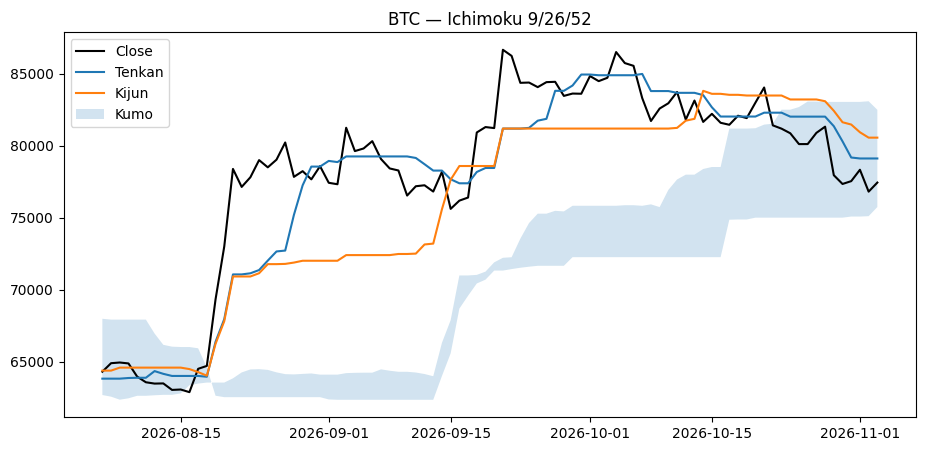

In [ ]:
def detecter_signaux(ich):
    if len(ich) < 2:
        return []
    a, b = ich.iloc[-2], ich.iloc[-1]
    valeurs = [a.tenkan, a.kijun, b.tenkan, b.kijun, a.kumo_haut, a.kumo_bas,
               b.kumo_haut, b.kumo_bas, a.close, b.close]
    if any(pd.isna(v) for v in valeurs):
        return []                                           # historique insuffisant (perp récent)
    res = []
    # --- Kumo Breakout ---
    if a.close <= a.kumo_haut and b.close > b.kumo_haut:
        res.append(("Kumo Breakout", "haussier"))
    if a.close >= a.kumo_bas and b.close < b.kumo_bas:
        res.append(("Kumo Breakout", "baissier"))
    return res

lignes = []
for coin, par_param in donnees_ichimoku.items():
    for nom, ich in par_param.items():
        for type_signal, sens in detecter_signaux(ich):
            lignes.append({"coin": coin, "params": nom, "signal": type_signal, "sens": sens,
                           "date_bougie": ich.iloc[-1]["date"].date(), "close": ich.iloc[-1]["close"]})

signaux = pd.DataFrame(lignes)
if signaux.empty:
    print("Aucun signal aujourd'hui.")
else:
    signaux = signaux.merge(perps[["coin", "dex", "vol_moy_90j_usd"]], on="coin")
    synthese = (signaux.groupby("coin")
                .agg(sens=("sens", lambda s: s.iloc[0] if s.nunique() == 1 else "mixte"),
                     signaux=("signal", lambda s: ", ".join(sorted(set(s)))),
                     params=("params", lambda s: ", ".join(sorted(set(s)))),
                     vol_moy_90j_usd=("vol_moy_90j_usd", "first"),
                     close=("close", "first"))
                .sort_values("vol_moy_90j_usd", ascending=False).reset_index())
    print(f"{len(synthese)} perps avec au moins un signal (dernière bougie : {signaux['date_bougie'].max()})")
    signaux = signaux.sort_values(["vol_moy_90j_usd", "signal", "params"], ascending=[False, True, True]).reset_index(drop=True)
    print("--- Détail (perps les plus liquides en premier) ---")
    display(signaux)
    print("--- Synthèse par actif ---")
    display(synthese)

def tracer(coin, params="9/26/52"):
    import matplotlib.pyplot as plt
    d = donnees_ichimoku[coin][params]
    plt.figure(figsize=(11, 5))
    plt.plot(d["date"], d["close"], label="Close", color="black")
    plt.plot(d["date"], d["tenkan"], label="Tenkan")
    plt.plot(d["date"], d["kijun"], label="Kijun")
    plt.fill_between(d["date"], d["span_a"], d["span_b"], alpha=0.2, label="Kumo")
    plt.title(f"{coin} — Ichimoku {params}"); plt.legend(); plt.show()
tracer("BTC")